# Lab 5: our CFD against Ghia and seven-Re coverage

This standalone CPU lab follows the original Week 1/1.2 and Week 4 CFD lessons.
It widens the **reference and experimental parameter range** to $Re=100,400,1000,3200,5000,7500,10000$.
Ghia's Tables I and II give 17 samples on each centreline, not a full flow field.
The square cavity has width $L$, lid speed $U$, $Re=UL/\nu$, and a discontinuous
moving lid at its upper corners. A smooth-lid or deep cavity is a different problem.

[Benchmark source and anomaly policy](../../references/ghia/README.md) ·
[Experiment, results and limitations](../../results/cavity_ghia_allre/README.md) ·
[Setup](../../START_HERE.md).

Three suspicious **printed** entries remain in the raw tables. We show both the
unfiltered score and a predeclared screened sensitivity score; we never silently
replace them with a plausible number. A train/test split by individual points
would leak the same Reynolds number into both sets.

For $N$ retained samples, report
$$E_u=\frac{\sqrt{\sum_i(\hat u_i-u_i)^2}}{\sqrt{\sum_i u_i^2}},\qquad
e_{\mathrm{RMS},u}/U=\sqrt{\frac1N\sum_i[(\hat u_i-u_i)/U]^2}.$$
Use the analogous definitions for $v$. The norm denominator is shared over the
profile, so a reference zero crossing causes no pointwise division by zero.
The code stores velocities already divided by $U$.


**Start with our computed solutions below.** This notebook now opens the native
FlowMLLab CFD archives, recomputes their errors, and plots CFD curves against
Ghia markers by default. It does not fit a curve through Ghia and call it CFD.
Retained CFD is available at Re=100, 400 and 1000; the four higher-Re fields are
still missing. The later neural section has a different data source and purpose.

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab5_All_Re_Ghia_Validation.ipynb)

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

### 1. Our CFD solutions, mesh changes and Ghia validation

Re=100 uses the existing staggered-grid SIMPLE runs on 32/64 cells. Re=400 and
1000 use the existing independent finite-difference streamfunction-vorticity
runs on 32/64/128 cells. Every archive is checked against its recorded SHA256.
For SIMPLE, centreline velocities come from the native MAC faces with the
prescribed wall values. For FD, we interpolate the actual two-dimensional field.

Table A recomputes the profile errors from these fields. Both the original
printed-data score and the predeclared sensitivity score are shown. Native
momentum and vorticity defects belong to different equations; their magnitudes
cannot rank the methods. A passed iteration gate does not establish mesh or
physical-time convergence.

In [2]:
if not (ROOT/'flowmllab/cavity_validation.py').is_file():
    raise RuntimeError('Use FlowMLLab v1.12.1 or later. Save your work, then update the checkout; do not overwrite your edited notebook.')
from flowmllab import cavity_validation as validation
cfd = validation.load_evidence(ROOT)
cfd_scores = pd.DataFrame(validation.score_rows(cfd))
print('Table A: measured errors of our retained CFD against Ghia')
columns = ['Re', 'method', 'cells', 'recorded_converged',
           'u_published_relative_l2', 'v_published_relative_l2',
           'v_screened_relative_l2', 'u_screened_rmse_U', 'v_screened_rmse_U',
           'recorded_steady_defect', 'native_equation']
display(cfd_scores[columns])
print('The relative-L2 columns are fractions (multiply by 100 for percent).')
print('Source archives and hashes:')
display(cfd_scores[['Re','cells','source','sha256']])

Table A: measured errors of our retained CFD against Ghia
The relative-L2 columns are fractions (multiply by 100 for percent).
Source archives and hashes:


,Re,method,cells,recorded_converged,u_published_relative_l2,v_published_relative_l2,v_screened_relative_l2,u_screened_rmse_U,v_screened_rmse_U,recorded_steady_defect,native_equation
0,100,simple,32,True,0.002847,0.026867,0.026867,0.001301,0.003584,8.538181e-08,momentum_residual_linf
1,100,simple,64,True,0.003954,0.032607,0.032607,0.001807,0.004350,9.283927e-08,momentum_residual_linf
2,400,streamfunction-vorticity,32,True,0.118876,0.267283,0.274048,0.050802,0.065468,1.398837e-08,steady_vorticity_linf
3,400,streamfunction-vorticity,64,True,0.029299,0.136233,0.058566,0.012521,0.013991,1.540279e-08,steady_vorticity_linf
4,400,streamfunction-vorticity,128,True,0.006019,0.146628,0.008972,0.002572,0.002143,1.496847e-08,steady_vorticity_linf
5,1000,streamfunction-vorticity,32,True,0.346874,0.601440,0.601440,0.141856,0.187336,1.927267e-08,steady_vorticity_linf
6,1000,streamfunction-vorticity,64,True,0.092799,0.130412,0.130412,0.037951,0.040621,2.593126e-08,steady_vorticity_linf
7,1000,streamfunction-vorticity,128,True,0.019881,0.017042,0.017042,0.008130,0.005308,2.892619e-08,steady_vorticity_linf


,Re,cells,source,sha256
0,100,32,results/week01_2_pressure_velocity/simple-re10...,643f7f3758403a5b3f0da5448edcc65946aa04509a29e5...
1,100,64,results/week01_2_pressure_velocity/simple-re10...,4ce6777c09aea15ef9235246dad10ca95f0c33eb4ebcf5...
2,400,32,results/week01_2_formulations/streamfunction-v...,bee636d538bba0384b9798e70d23b5f2bbfd77e5ca495d...
3,400,64,results/week01_2_formulations/streamfunction-v...,452c840729aecbb74f9486c72f584ae07c0c374410de09...
4,400,128,results/week01_2_formulations/streamfunction-v...,0189db217fbca28715aba673fe3285180094230c028f92...
5,1000,32,results/week01_2_formulations/streamfunction-v...,71aa482837048e8c2ecb32ab461c945f291f98f202d1b6...
6,1000,64,results/week01_2_formulations/streamfunction-v...,3002469df010b5ce884aae92b48042c493708eb8f9eddf...
7,1000,128,results/week01_2_formulations/streamfunction-v...,8b72232e01afa6429ba9f72199b901fe7f90d266ed169c...


Actual FlowMLLab CFD streamlines: SIMPLE at Re=100; FD at Re=400 and 1000.
Re=100: our CFD on retained grids versus Ghia, then signed sample errors
Re=400: our CFD on retained grids versus Ghia, then signed sample errors
Re=1000: our CFD on retained grids versus Ghia, then signed sample errors


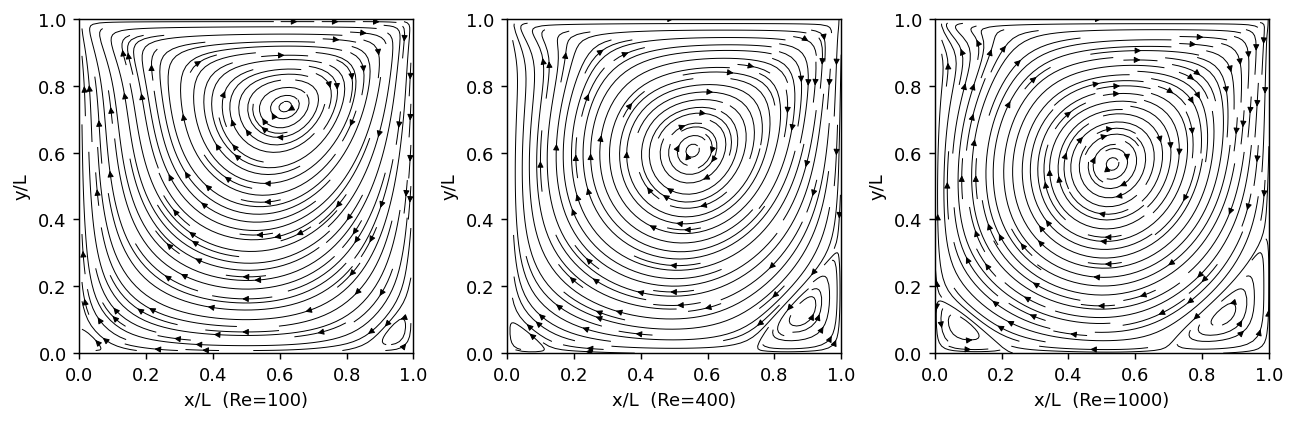

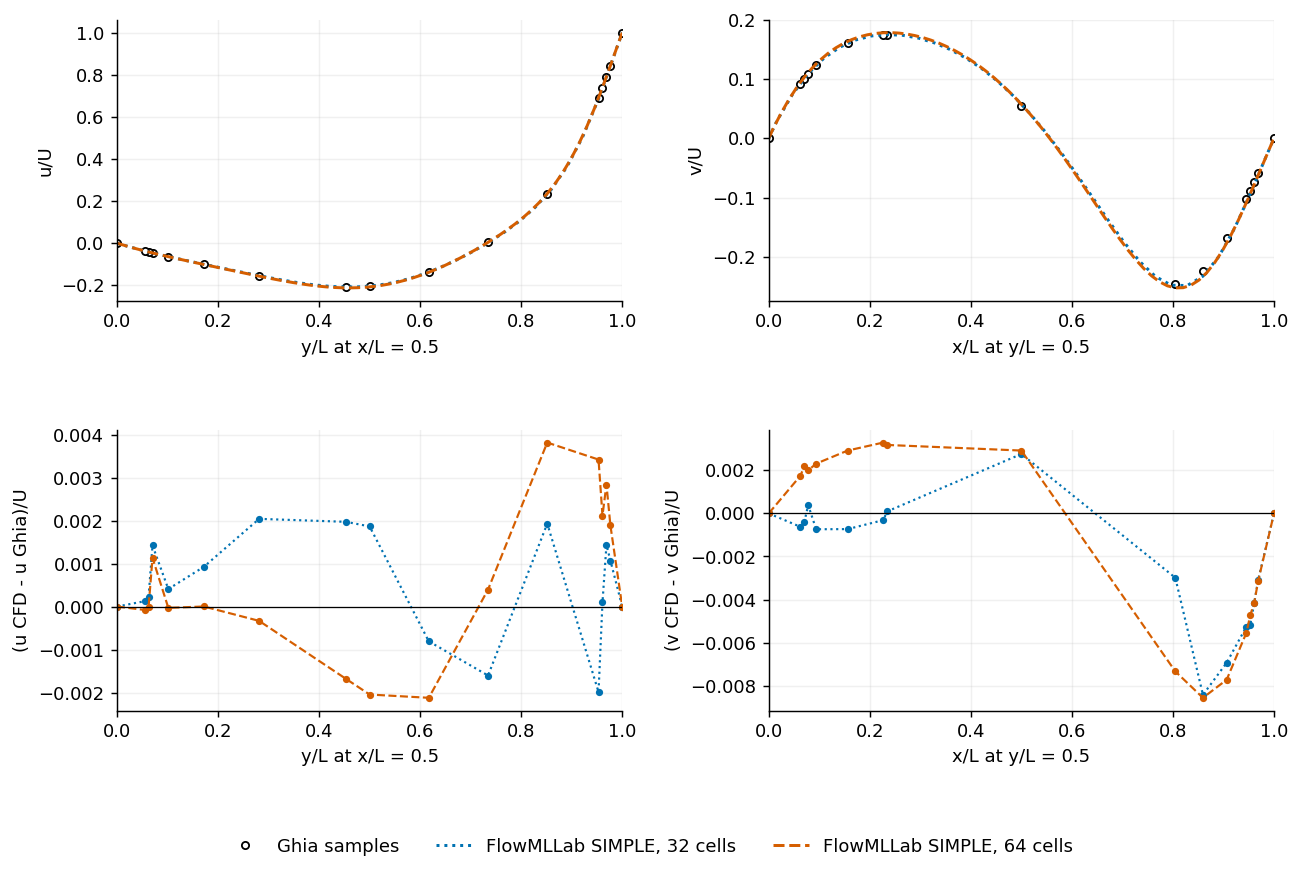

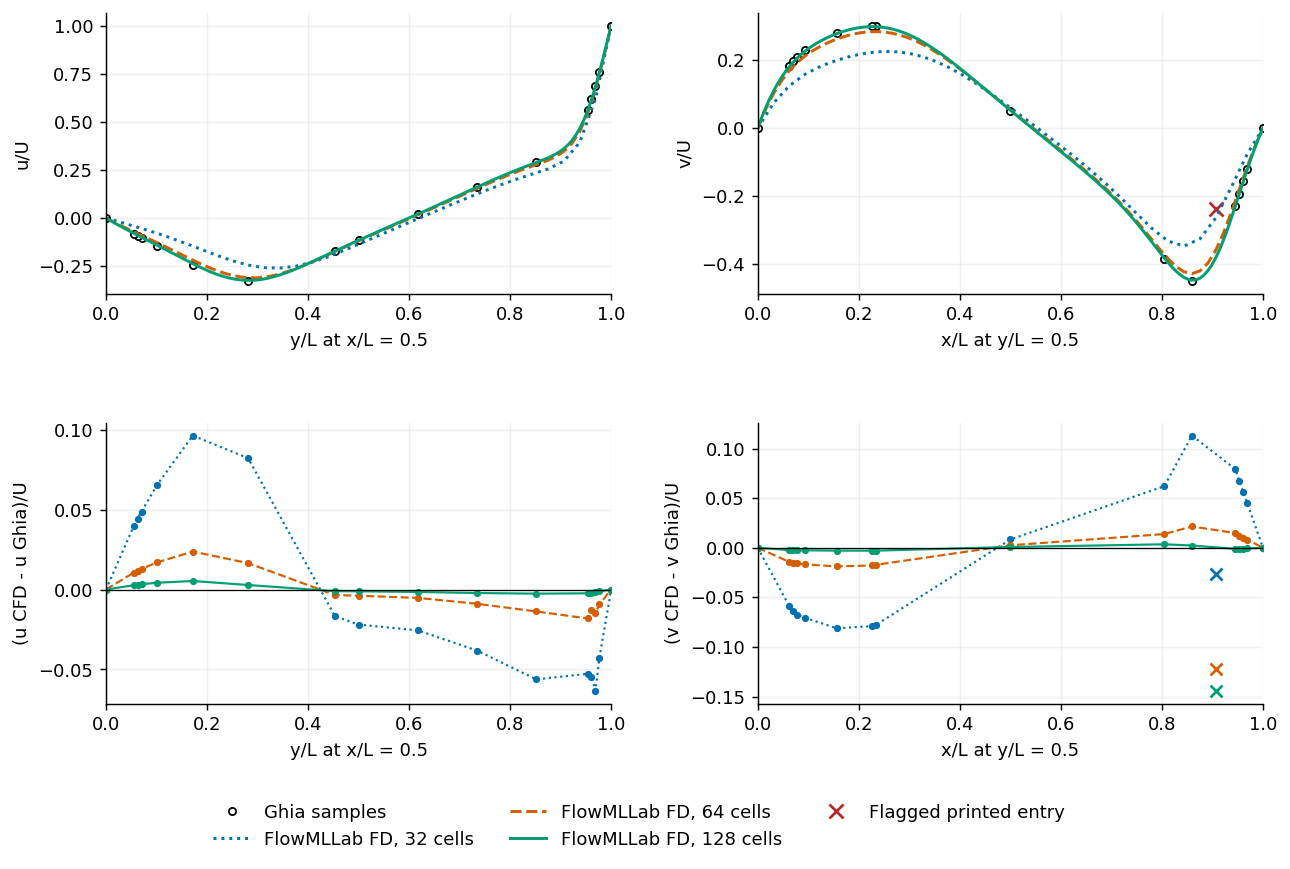

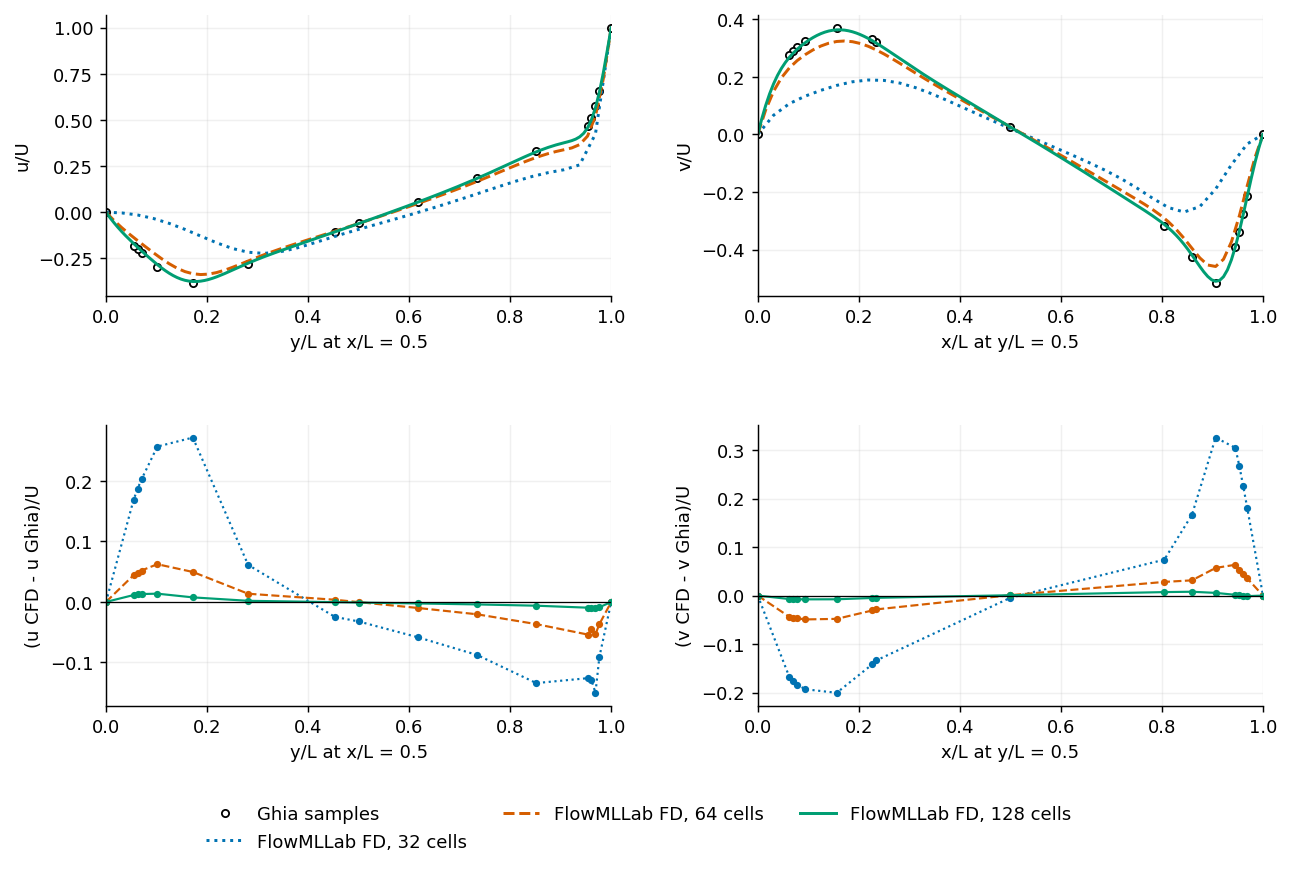

In [3]:
print('Actual FlowMLLab CFD streamlines: SIMPLE at Re=100; FD at Re=400 and 1000.')
validation.plot_streamlines(cfd)
plt.show()
for re in (100, 400, 1000):
    print(f'Re={re}: our CFD on retained grids versus Ghia, then signed sample errors')
    validation.plot_profiles(cfd, re)
    plt.show()

Read the changes in the velocity profiles before reading the scalar score.
At Re=400, the marked printed v value near x/L=0.9063 strongly affects the
all-point norm. Its signed discrepancy remains visible; screening does not
replace the published value. At Re=100, these two SIMPLE grids do not give a
monotone Ghia-error reduction. Report that outcome rather than claiming a
successful convergence study. The original source and histories remain in
[Re=100 evidence](../../results/week01_2_pressure_velocity/README.md) and
[Re=400/1000 evidence](../../results/week01_2_formulations/README.md).

### 2. What we have for neural learning on the Ghia cases

There are two different retained experiments:

* **Full fields:** the existing POD-DeepONet learns 65 by 65 velocity and pressure
  fields from our CFD over Re=100--400. Its blind cases are Re=175, 275 and 375.
  Ghia checks at Re=100 and 400 are not unseen-Re tests of that model.
  [Full-field results and protocol](../../results/pod_deeponet/README.md).
* **All-seven-Re profile study:** a small MLP learns u(y) and v(x) directly from
  Ghia centreline samples. Training uses Re=100,1000,5000,10000; validation uses
  400; complete test cases are 3200 and 7500. Adam, L-BFGS, their sequence, network
  depth and wall-data weights are compared across three seeds. These results do
  not supply the missing high-Re CFD fields or demonstrate a high-Re PINN solve.

The figures below show the frozen baseline, selected network and interpolation
against the held-out Ghia samples. Their lower panels show signed discrepancies
at measured reference locations. Curves are three-seed means; Table B averages
individual-seed errors. The original printed-data sensitivities remain in the
CSV. [Lab 6](W4_Lab6_Ghia_Profile_Optimizer_Depth.ipynb) gives the complete training
protocol, all seven plots, source models and architecture/optimizer exercises.

Table B: mean u/v RMSE divided by U, averaged over individual seeds
Re=3200: held-out Ghia-profile prediction; these curves are not a CFD solve
Re=7500: held-out Ghia-profile prediction; these curves are not a CFD solve
The selected neural model improves over Adam, but log-Re interpolation wins both tests.


Re,3200,7500
model,,
adam_2,0.033949,0.038002
hybrid_5_wall,0.019739,0.005627
linear_logRe,0.016294,0.005176


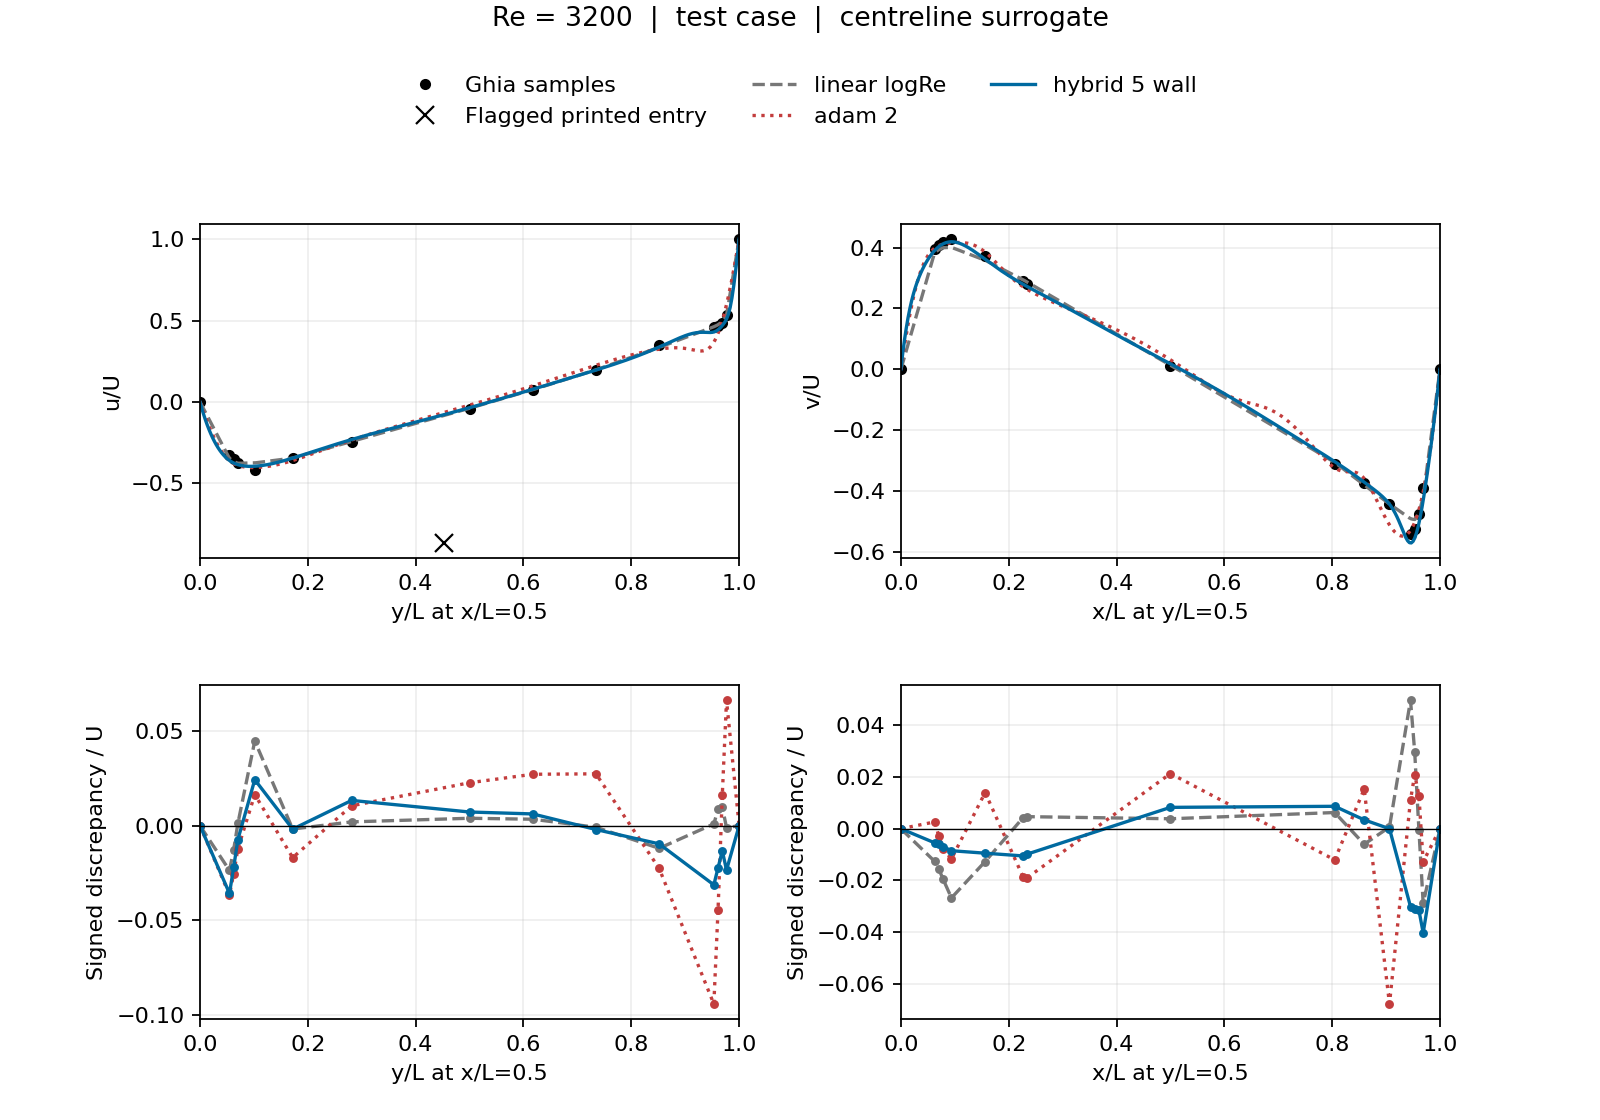

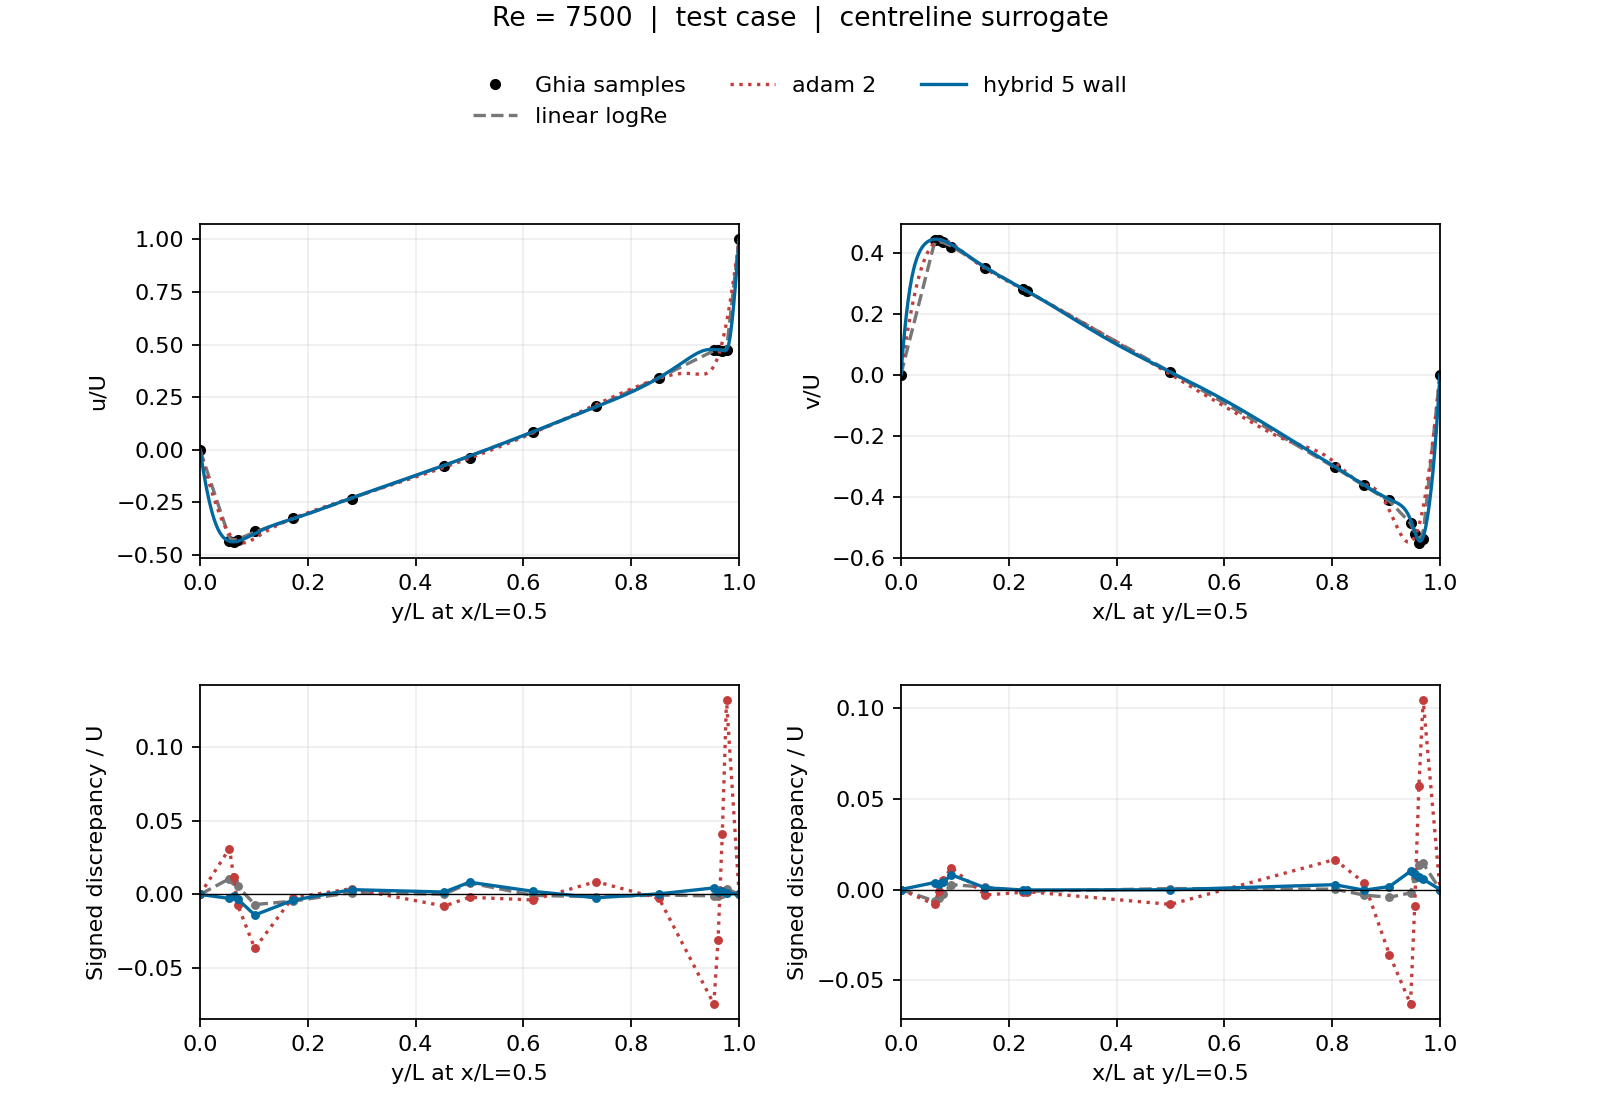

In [4]:
course.verify_frozen_models(ROOT)
neural_folder = ROOT/'results/cavity_ghia_allre'
measured = pd.read_csv(neural_folder/'scores.csv')
per_seed = measured.groupby(['model','Re','role','seed'])['rmse_U'].mean().reset_index()
test = per_seed[(per_seed.role == 'test') & per_seed.model.isin(
    ['adam_2','hybrid_5_wall','linear_logRe'])]
print('Table B: mean u/v RMSE divided by U, averaged over individual seeds')
display(test.groupby(['model','Re']).rmse_U.mean().unstack('Re'))
for re in (3200, 7500):
    print(f'Re={re}: held-out Ghia-profile prediction; these curves are not a CFD solve')
    display(Image(filename=str(neural_folder/f're{re}_profiles.png'), width=800))
print('The selected neural model improves over Adam, but log-Re interpolation wins both tests.')

### 3. Coverage and the remaining high-Re CFD work

Table C gives all seven reference cases and explicitly identifies the missing
CFD fields. A Ghia table is not a full field, and a profile-regression prediction
does not fill that gap. For each additional CFD case retain grid, time step,
convection, residual history, wall treatment and both velocity profiles. Compare
three grids and a halved time step, and inspect stationarity, mass balance and
vortex locations before using the field for machine learning. Pressure requires
an independent validation: Ghia's velocity samples do not provide one.

In [5]:
print('Table C: reference and retained CFD coverage')
display(pd.DataFrame(course.coverage(ROOT)))
# Reference-only figures are optional: the default plots above contain OUR solutions.
SHOW_REFERENCE_ONLY = False
if SHOW_REFERENCE_ONLY:
    for re in ghia.REYNOLDS:
        print(f'Re={re}: published samples only')
        course.plot_reference(re)
        plt.show()

Table C: reference and retained CFD coverage


,Re,reference_samples,flagged_samples,profile_study_role,retained_field,scope
0,100,34,0,train,results/week01_2_pressure_velocity/simple-re10...,retained evidence; inspect its own mesh/steady...
1,400,34,1,validation,results/week01_2_formulations/streamfunction-v...,retained evidence; inspect its own mesh/steady...
2,1000,34,0,train,results/week01_2_formulations/streamfunction-v...,retained evidence; inspect its own mesh/steady...
3,3200,34,1,test,None,no retained full field; benchmark table only
4,5000,34,0,train,None,no retained full field; benchmark table only
5,7500,34,0,test,None,no retained full field; benchmark table only
6,10000,34,1,train,None,no retained full field; benchmark table only


In [6]:
# Optional new CFD: choose one case and audit it before treating it as a field label.
RUN_NEW_CFD = False
RE_TO_SOLVE = 3200
CELLS = 128
if RUN_NEW_CFD:
    from flowmllab.streamfunction_experiments import run_streamfunction
    field = run_streamfunction(reynolds=RE_TO_SOLVE, cells=CELLS,
                              dt=0.0005, max_steps=400000, progress=False)
    display({k:field[k] for k in ['status','steps','steady_vorticity_linf',
                                'continuity_linf','ghia_u_relative_l2','ghia_v_relative_l2']})
    display(course.compare_field(RE_TO_SOLVE,field['x'],field['y'],field['u'],field['v']))
else:
    print('Retained CFD and neural results above were loaded and evaluated; no new CFD run requested.')

Retained CFD and neural results above were loaded and evaluated; no new CFD run requested.


### Specific student tasks

1. **Table A and the three CFD figures:** report the u/v errors for every retained
   grid. Locate the largest signed discrepancy and explain the nonmonotone
   Re=100 result. For Re=400, explain the difference between raw and screened v
   norms using the marked sample. Do not choose a mask from your observed error.
2. **Spatial evidence:** identify the primary vortex in each actual CFD field.
   Describe which corner structures the present grids resolve. Ghia's two
   centreline tables alone cannot validate a complete vortex map or pressure.
3. **Table B and the two test figures:** compare Adam, the selected network and
   interpolation separately at Re=3200 and 7500. State where the neural model
   gains and loses, and distinguish seed-mean error from error of the mean curve.
4. **Information and test sets:** list the different training labels and blind
   Re values of the full-field POD-DeepONet and the centreline MLP. Explain why
   a successful profile fit is not independent validation of a flow solver.
5. **Table C:** write an admission decision for each Re. Design a three-grid and
   two-time-step CFD experiment for one missing high-Re field. Keep missing,
   nonstationary and failed cases explicitly marked.
6. **Algorithm comparison:** use the original Week 1.2 matched SIMPLE/PISO/PIMPLE
   runs to compare pressure solves and elapsed time at equal achieved accuracy.
   SIMPLE iterations are not physical time. Do not infer an algorithm ranking
   by comparing the different Re/method combinations in this notebook.